# Proyecto grupo 4

Importamos la libreria

In [72]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn_extra.cluster import KMedoids
from umap import UMAP
from sklearn.cluster import DBSCAN


In [73]:
df=pd.read_excel("base_reatail_canal_moderno.xlsx")

In [74]:
df.head()

,marca,tamano,empaque,und_x_pack,segmento,periodo,local,regional,formato,venta_id,unidades,hls,is_our_product
0,Brand_0,269,LATA,6,PREMIUM & SP,2025-08,STORE_175,COSTA,grande,5.7,1,0.01614,1
1,Brand_1,330,NR,1,PREMIUM & SP,2025-08,STORE_32,COSTA,pequeño,1.0,1,0.00330,0
2,Brand_2,250,LATA,10,PREMIUM & SP,2025-08,STORE_47,COSTA,grande,261.8,25,0.62500,0
3,Brand_0,355,LATA,1,PREMIUM & SP,2025-08,STORE_13,COSTA,mediano,0.0,0,0.00000,1
4,Brand_3,269,LATA,6,CORE,2025-08,STORE_10,SIERRA,grande,34.3,9,0.14526,1


In [75]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226813 entries, 0 to 226812
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   marca           226813 non-null  object 
 1   tamano          226813 non-null  int64  
 2   empaque         226813 non-null  object 
 3   und_x_pack      226813 non-null  int64  
 4   segmento        226813 non-null  object 
 5   periodo         226813 non-null  object 
 6   local           226813 non-null  object 
 7   regional        226813 non-null  object 
 8   formato         226813 non-null  object 
 9   venta_id        226813 non-null  float64
 10  unidades        226813 non-null  int64  
 11  hls             226813 non-null  float64
 12  is_our_product  226813 non-null  int64  
dtypes: float64(2), int64(4), object(7)
memory usage: 22.5+ MB


In [76]:
df.describe()

,tamano,und_x_pack,venta_id,unidades,hls,is_our_product
count,226813.000000,226813.000000,226813.000000,226813.000000,226813.000000,226813.000000
mean,338.372651,5.539374,226.730812,59.883613,0.788721,0.507996
std,68.618269,3.416608,1076.675961,760.069437,4.016698,0.499937
min,207.000000,1.000000,-121.600000,-46.000000,-0.514800,0.000000
25%,330.000000,6.000000,11.400000,3.000000,0.039600,0.000000
50%,330.000000,6.000000,39.800000,8.000000,0.127800,1.000000
75%,355.000000,6.000000,145.500000,26.000000,0.475200,1.000000
max,750.000000,24.000000,87027.200000,83282.000000,392.594400,1.000000


Limpiamos los valores negativos y ceros en venta_id, unidades y hls

In [77]:
df2=df[(df["venta_id"]>0)&(df["unidades"]>0)&(df["hls"]>0)]

In [78]:
df3=df2.copy()
df3

,marca,tamano,empaque,und_x_pack,segmento,periodo,local,regional,formato,venta_id,unidades,hls,is_our_product
0,Brand_0,269,LATA,6,PREMIUM & SP,2025-08,STORE_175,COSTA,grande,5.7,1,0.01614,1
1,Brand_1,330,NR,1,PREMIUM & SP,2025-08,STORE_32,COSTA,pequeño,1.0,1,0.00330,0
2,Brand_2,250,LATA,10,PREMIUM & SP,2025-08,STORE_47,COSTA,grande,261.8,25,0.62500,0
4,Brand_3,269,LATA,6,CORE,2025-08,STORE_10,SIERRA,grande,34.3,9,0.14526,1
5,Brand_4,355,LATA,12,PREMIUM & SP,2025-08,STORE_81,COSTA,mediano,53.6,4,0.17040,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
226808,Brand_0,355,LATA,6,PREMIUM & SP,2025-01,STORE_114,COSTA,pequeño,81.3,11,0.23430,1
226809,Brand_8,330,NR,6,CORE,2025-06,STORE_56,COSTA,mediano,12.8,2,0.03960,0
226810,Brand_4,355,LATA,1,PREMIUM & SP,2025-07,STORE_56,COSTA,mediano,1.4,1,0.00355,0
226811,Brand_10,500,NR,1,PREMIUM & SP,2025-07,STORE_63,COSTA,otros,11.3,6,0.03000,0


In [79]:
df3["is_COSTA"]=np.where(df3.regional == "COSTA", 1, 0)
df3= df3.drop("regional", axis=1)
df3

,marca,tamano,empaque,und_x_pack,segmento,periodo,local,formato,venta_id,unidades,hls,is_our_product,is_COSTA
0,Brand_0,269,LATA,6,PREMIUM & SP,2025-08,STORE_175,grande,5.7,1,0.01614,1,1
1,Brand_1,330,NR,1,PREMIUM & SP,2025-08,STORE_32,pequeño,1.0,1,0.00330,0,1
2,Brand_2,250,LATA,10,PREMIUM & SP,2025-08,STORE_47,grande,261.8,25,0.62500,0,1
4,Brand_3,269,LATA,6,CORE,2025-08,STORE_10,grande,34.3,9,0.14526,1,0
5,Brand_4,355,LATA,12,PREMIUM & SP,2025-08,STORE_81,mediano,53.6,4,0.17040,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
226808,Brand_0,355,LATA,6,PREMIUM & SP,2025-01,STORE_114,pequeño,81.3,11,0.23430,1,1
226809,Brand_8,330,NR,6,CORE,2025-06,STORE_56,mediano,12.8,2,0.03960,0,1
226810,Brand_4,355,LATA,1,PREMIUM & SP,2025-07,STORE_56,mediano,1.4,1,0.00355,0,1
226811,Brand_10,500,NR,1,PREMIUM & SP,2025-07,STORE_63,otros,11.3,6,0.03000,0,1


Reestructuramos el dataset de transacciones a perfil por local

In [80]:
df_local = df3.groupby("local").agg({
    "unidades":"sum",
    "hls":"sum",
    "venta_id": "sum",
    "is_COSTA":"mean",
}).reset_index()
df_local

,local,unidades,hls,venta_id,is_COSTA
0,STORE_0,84116,1670.73341,487506.9,1.0
1,STORE_1,56975,1162.68266,337469.9,1.0
2,STORE_10,39531,684.32987,202220.9,0.0
3,STORE_100,7044,121.99652,35181.7,0.0
4,STORE_101,18365,336.86479,101352.2,0.0
...,...,...,...,...,...
201,STORE_95,22950,448.19926,125746.6,1.0
202,STORE_96,11662,226.84512,65147.7,1.0
203,STORE_97,9523,169.24997,48977.1,0.0
204,STORE_98,50468,1012.15492,281219.8,1.0


Creamos mini datasets para cada variable categorica en proporcion por tienda para luego unirlos

In [81]:
empaque_dist = pd.crosstab(df3['local'], df3['empaque'], normalize='index')
segmento_dist = pd.crosstab(df3['local'], df3['segmento'], normalize='index')
undxpack_dist = pd.crosstab(df3['local'], df3['und_x_pack'], normalize='index')
formato_dist = pd.crosstab(df3['local'], df3['formato'], normalize='index')

Creamos un minidaset a partir de periodo para tener la evolucion mensual de ventas

In [82]:
pivot_mes = df3.pivot_table(
    index='local',
    columns='periodo',
    values='venta_id',
    aggfunc='sum',
    fill_value=0
)
pivot_mes = pivot_mes.reset_index()
pivot_mes

periodo,local,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
0,STORE_0,29011.4,28689.8,38419.6,35204.0,42553.9,37020.5,37234.1,35851.7,33151.2,38240.0,55464.3,76666.4
1,STORE_1,20866.7,18341.9,26687.0,21335.3,28331.8,26232.2,21558.8,29750.6,23887.1,26328.1,43999.3,50151.1
2,STORE_10,11387.8,11547.0,14499.5,13776.4,17990.6,16610.1,14124.8,17317.2,14843.7,17134.4,21690.3,31299.1
3,STORE_100,2292.0,2202.9,2785.1,1810.9,3035.9,2907.8,3420.9,3302.8,2952.0,3010.3,2278.7,5182.4
4,STORE_101,5627.6,5218.9,8045.5,6874.8,9212.9,8988.8,7947.8,9347.7,7720.3,7627.6,9508.6,15231.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...
201,STORE_95,6302.3,5209.1,10873.5,8452.0,13144.7,11105.6,9992.1,10951.4,9776.8,9801.1,10558.0,19580.0
202,STORE_96,4405.3,2437.9,5206.8,4875.4,5779.5,5509.4,4307.7,5498.9,4355.8,5297.8,7754.6,9718.6
203,STORE_97,3699.4,3145.7,4433.5,3456.6,4430.6,4035.0,4473.2,4161.6,3670.7,3762.1,3149.7,6559.0
204,STORE_98,14405.2,11794.6,27437.1,18989.2,26132.1,22814.0,20372.6,29907.2,21095.7,24254.2,20960.7,43057.2


Creamos una minisaet para saber cuantas marcas se vende por tienda y cuantas de estan son nuestras y posteriormente sacamos el ratio para saber el porcentaje de nuestras marcas vs la competencia

In [83]:
total_marcas = df3.groupby('local')['marca'].nunique()

marcas_mias = (
    df3[df3['is_our_product'] == 1]
    .groupby('local')['marca']
    .nunique()
)

df_marcas = pd.concat(
    [total_marcas, marcas_mias],
    axis=1
).reset_index()

df_marcas.columns = [
    'local',
    'total_marcas',
    'marcas_mias'
]

df_marcas = df_marcas.fillna(0)

# Ratio de marcas propias
df_marcas['ratio_marcas_mias'] = (
    df_marcas['marcas_mias'] /
    df_marcas['total_marcas']
)

Unificamos todo

In [84]:
df_final = df_local.merge(empaque_dist, on='local')
df_final = df_final.merge(segmento_dist, on='local')
df_final = df_final.merge(undxpack_dist, on='local')
df_final = df_final.merge(formato_dist, on='local')
df_final = df_final.merge(pivot_mes, on='local')
df_final = df_final.merge(df_marcas, on='local')

In [85]:
df_final

,local,unidades,hls,venta_id,is_COSTA,LATA,NR,RB,CORE,PREMIUM & SP,VALUE,1,2,4,6,10,12,24,grande,mediano,otros,pequeño,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,total_marcas,marcas_mias,ratio_marcas_mias
0,STORE_0,84116,1670.73341,487506.9,1.0,0.586595,0.413405,0.0,0.305094,0.675067,0.019839,0.280429,0.0,0.0,0.585523,0.020912,0.105630,0.007507,0.0,1.0,0.0,0.0,29011.4,28689.8,38419.6,35204.0,42553.9,37020.5,37234.1,35851.7,33151.2,38240.0,55464.3,76666.4,27,10.0,0.370370
1,STORE_1,56975,1162.68266,337469.9,1.0,0.581368,0.418632,0.0,0.325472,0.669811,0.004717,0.260024,0.0,0.0,0.601415,0.022995,0.109080,0.006486,0.0,1.0,0.0,0.0,20866.7,18341.9,26687.0,21335.3,28331.8,26232.2,21558.8,29750.6,23887.1,26328.1,43999.3,50151.1,28,10.0,0.357143
2,STORE_10,39531,684.32987,202220.9,0.0,0.570588,0.429412,0.0,0.288824,0.706471,0.004706,0.281176,0.0,0.0,0.582941,0.022941,0.105882,0.007059,1.0,0.0,0.0,0.0,11387.8,11547.0,14499.5,13776.4,17990.6,16610.1,14124.8,17317.2,14843.7,17134.4,21690.3,31299.1,29,9.0,0.310345
3,STORE_100,7044,121.99652,35181.7,0.0,0.555041,0.444959,0.0,0.375435,0.624565,0.000000,0.191194,0.0,0.0,0.710313,0.028969,0.056779,0.012746,0.0,0.0,0.0,1.0,2292.0,2202.9,2785.1,1810.9,3035.9,2907.8,3420.9,3302.8,2952.0,3010.3,2278.7,5182.4,16,8.0,0.500000
4,STORE_101,18365,336.86479,101352.2,0.0,0.590909,0.409091,0.0,0.296165,0.683239,0.020597,0.264205,0.0,0.0,0.586648,0.026278,0.113636,0.009233,0.0,1.0,0.0,0.0,5627.6,5218.9,8045.5,6874.8,9212.9,8988.8,7947.8,9347.7,7720.3,7627.6,9508.6,15231.7,25,8.0,0.320000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
201,STORE_95,22950,448.19926,125746.6,1.0,0.572067,0.427933,0.0,0.410056,0.589944,0.000000,0.155307,0.0,0.0,0.748603,0.027933,0.065922,0.002235,0.0,0.0,0.0,1.0,6302.3,5209.1,10873.5,8452.0,13144.7,11105.6,9992.1,10951.4,9776.8,9801.1,10558.0,19580.0,15,8.0,0.533333
202,STORE_96,11662,226.84512,65147.7,1.0,0.556551,0.443449,0.0,0.410974,0.589026,0.000000,0.147816,0.0,0.0,0.755879,0.024636,0.068309,0.003359,0.0,0.0,0.0,1.0,4405.3,2437.9,5206.8,4875.4,5779.5,5509.4,4307.7,5498.9,4355.8,5297.8,7754.6,9718.6,15,8.0,0.533333
203,STORE_97,9523,169.24997,48977.1,0.0,0.562630,0.437370,0.0,0.369520,0.630480,0.000000,0.184760,0.0,0.0,0.705637,0.031315,0.067850,0.010438,0.0,0.0,0.0,1.0,3699.4,3145.7,4433.5,3456.6,4430.6,4035.0,4473.2,4161.6,3670.7,3762.1,3149.7,6559.0,16,8.0,0.500000
204,STORE_98,50468,1012.15492,281219.8,1.0,0.586876,0.413124,0.0,0.411275,0.588725,0.000000,0.190388,0.0,0.0,0.708872,0.033272,0.061922,0.005545,0.0,0.0,0.0,1.0,14405.2,11794.6,27437.1,18989.2,26132.1,22814.0,20372.6,29907.2,21095.7,24254.2,20960.7,43057.2,14,7.0,0.500000


In [86]:
df_final.describe()

,unidades,hls,venta_id,is_COSTA,LATA,NR,RB,CORE,PREMIUM & SP,VALUE,1,2,4,6,10,12,24,grande,mediano,otros,pequeño,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,total_marcas,marcas_mias,ratio_marcas_mias
count,206.000000,206.000000,2.060000e+02,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000
mean,65933.635922,868.407369,2.496394e+05,0.805825,0.570159,0.428693,0.001148,0.358572,0.636676,0.004752,0.209047,0.000621,0.000375,0.672580,0.031997,0.076693,0.008688,0.189320,0.155340,0.067961,0.587379,13250.586893,12276.629126,20240.763107,16225.464563,19941.723301,17541.241748,17083.726214,23340.032524,16163.289320,21255.631553,31716.978155,40603.374757,18.839806,7.878641,0.439034
std,120927.354244,1149.552356,3.283867e+05,0.396528,0.029589,0.029411,0.006719,0.071113,0.066936,0.008586,0.069613,0.002173,0.001205,0.081865,0.032217,0.026557,0.005595,0.392717,0.363111,0.252292,0.493505,20609.438859,18733.277866,30734.282355,23515.067966,25953.319458,21919.656510,23476.775477,34981.446201,19173.148069,31527.522546,46987.250121,51884.588138,7.037777,1.434702,0.096860
min,249.000000,3.791600,1.272800e+03,0.000000,0.371429,0.325301,0.000000,0.000000,0.536730,0.000000,0.000000,0.000000,0.000000,0.377778,0.006033,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,8040.250000,147.088842,4.280103e+04,1.000000,0.556731,0.412410,0.000000,0.315001,0.586244,0.000000,0.158291,0.000000,0.000000,0.617175,0.022543,0.060088,0.005526,0.000000,0.000000,0.000000,0.000000,1377.750000,1084.300000,1783.875000,1963.375000,3090.050000,3208.725000,3405.825000,4208.275000,3551.125000,4310.950000,4421.750000,9128.000000,14.000000,7.000000,0.362105
50%,19764.000000,384.835685,1.114123e+05,1.000000,0.573233,0.425686,0.000000,0.370838,0.629059,0.000000,0.196338,0.000000,0.000000,0.690774,0.027961,0.071297,0.007479,0.000000,0.000000,0.000000,1.000000,5656.700000,4724.600000,9024.900000,6900.700000,9313.550000,8937.200000,8140.200000,10040.450000,8145.400000,10181.150000,10718.700000,20420.100000,15.000000,8.000000,0.500000
75%,66968.500000,1105.277358,3.332070e+05,1.000000,0.586820,0.441779,0.000000,0.413756,0.675050,0.004736,0.253114,0.000000,0.000000,0.736040,0.033729,0.096824,0.010777,0.000000,0.000000,0.000000,1.000000,15671.300000,14106.650000,25894.775000,20944.400000,26939.175000,24900.125000,21522.400000,29556.475000,23488.000000,26937.325000,43265.075000,52929.775000,25.000000,9.000000,0.500000
max,874074.000000,6805.679780,1.761585e+06,1.000000,0.674699,0.628571,0.060230,0.463270,1.000000,0.041096,0.389912,0.011442,0.006329,0.807692,0.349398,0.134156,0.049383,1.000000,1.000000,1.000000,1.000000,138261.200000,101530.600000,194294.500000,137941.800000,123270.400000,121903.400000,172220.800000,272391.200000,87019.700000,288974.300000,326733.600000,305710.500000,37.000000,10.000000,0.562500


Matriz de correlacion

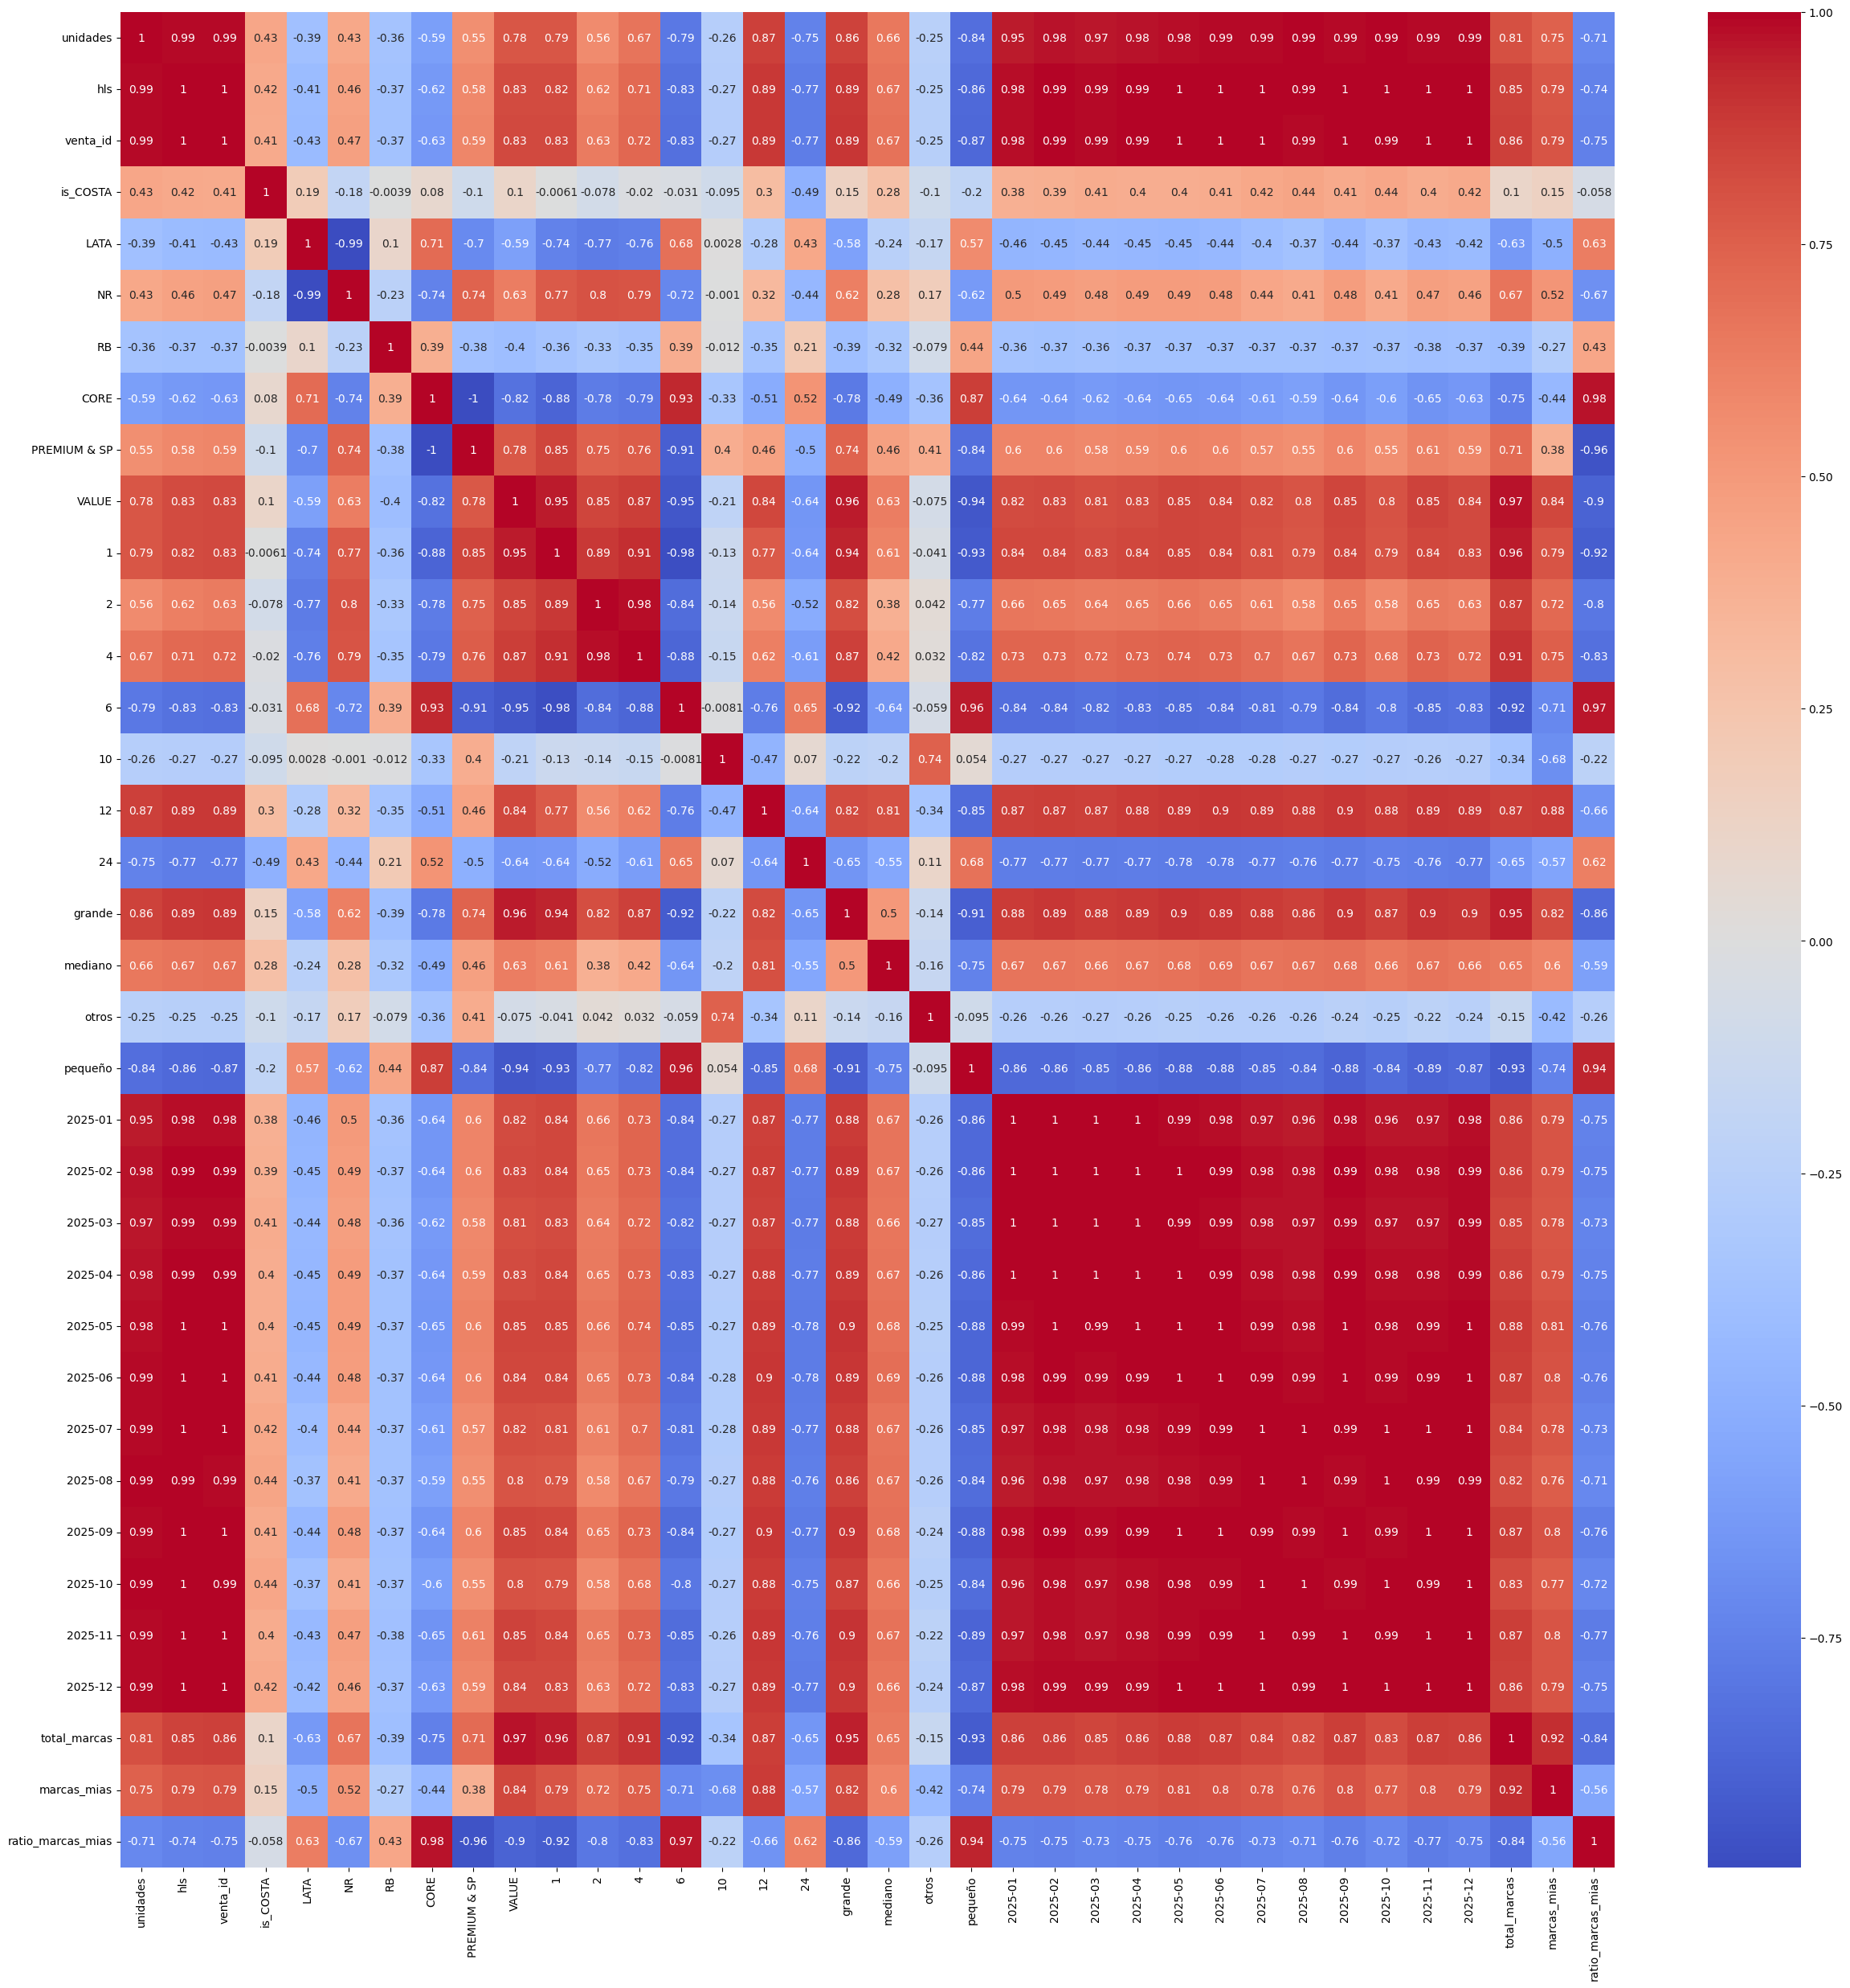

In [87]:
matriz_corr = df_final.corr(numeric_only=True)
plt.figure(figsize=(30,30))
sns.heatmap(matriz_corr.corr(), annot=True, cmap='coolwarm')
plt.show()

Eliminamos las variables que no vamos a seleccionar para nuestro modelo

In [88]:
df_final = df_final.drop(['local',"unidades","2025-01","2025-02","2025-03","2025-04","2025-05","2025-06","2025-07","2025-08","2025-09","2025-10","2025-11","2025-12"],axis=1)
ds=df_final.copy()

In [89]:
scaler = MinMaxScaler()
ds.columns = ds.columns.astype(str)
scaler.fit(ds)
scaled_ds = pd.DataFrame(scaler.transform(ds),columns= ds.columns )
scaled_ds

,hls,venta_id,is_COSTA,LATA,NR,RB,CORE,PREMIUM & SP,VALUE,1,2,4,6,10,12,24,grande,mediano,otros,pequeño,total_marcas,marcas_mias,ratio_marcas_mias
0,0.245070,0.276220,1.0,0.709488,0.290512,0.0,0.658566,0.298610,0.482752,0.719210,0.0,0.0,0.483224,0.043331,0.787369,0.152011,0.0,1.0,0.0,0.0,0.722222,1.0,0.658436
1,0.170378,0.190987,1.0,0.692252,0.307748,0.0,0.702553,0.287265,0.114780,0.666877,0.0,0.0,0.520190,0.049400,0.813086,0.131338,0.0,1.0,0.0,0.0,0.750000,1.0,0.634921
2,0.100051,0.114155,0.0,0.656707,0.343293,0.0,0.623445,0.366397,0.114510,0.721128,0.0,0.0,0.477219,0.049242,0.789249,0.142941,1.0,0.0,0.0,0.0,0.777778,0.9,0.551724
3,0.017378,0.019263,0.0,0.605440,0.394560,0.0,0.810401,0.189599,0.000000,0.490350,0.0,0.0,0.773491,0.066796,0.423230,0.258111,0.0,0.0,0.0,1.0,0.416667,0.8,0.888889
4,0.048968,0.056853,0.0,0.723713,0.276287,0.0,0.639292,0.316249,0.501184,0.677600,0.0,0.0,0.485841,0.058961,0.847048,0.186967,0.0,1.0,0.0,0.0,0.666667,0.8,0.568889
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
201,0.065336,0.070711,1.0,0.661583,0.338417,0.0,0.885133,0.114867,0.000000,0.398313,0.0,0.0,0.862557,0.063780,0.491383,0.045251,0.0,0.0,0.0,1.0,0.388889,0.8,0.948148
202,0.032793,0.036286,1.0,0.610421,0.389579,0.0,0.887116,0.112884,0.000000,0.379102,0.0,0.0,0.879480,0.054178,0.509177,0.068029,0.0,0.0,0.0,1.0,0.388889,0.8,0.948148
203,0.024325,0.027100,0.0,0.630467,0.369533,0.0,0.797634,0.202366,0.000000,0.473850,0.0,0.0,0.762614,0.073630,0.505753,0.211378,0.0,0.0,0.0,1.0,0.416667,0.8,0.888889
204,0.148248,0.159033,1.0,0.710415,0.289585,0.0,0.887766,0.112234,0.000000,0.488285,0.0,0.0,0.770141,0.079328,0.461571,0.112292,0.0,0.0,0.0,1.0,0.361111,0.7,0.888889


Segmentando con KMEANS

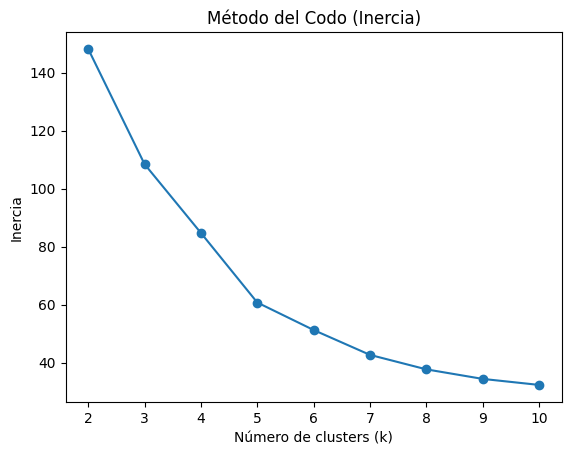

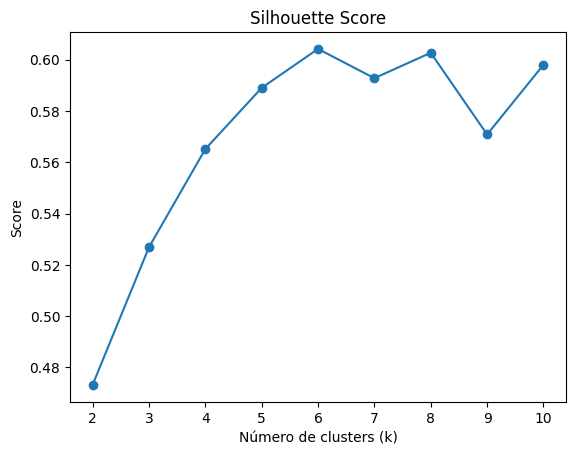

In [90]:
inertia = []
silhouette = []
K_range = range(2, 11)  # desde 2 hasta 10 clusters

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_ds)
    
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(scaled_ds, kmeans.labels_))

# 📊 Gráfico método del codo
plt.figure()
plt.plot(K_range, inertia, marker='o')
plt.title("Método del Codo (Inercia)")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.show()

# 📊 Gráfico silhouette
plt.figure()
plt.plot(K_range, silhouette, marker='o')
plt.title("Silhouette Score")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Score")
plt.show()

k=6 es el número óptimo de clusters, ya que representa el punto de equilibrio donde la inercia del Método del Codo comienza a estabilizarse y, simultáneamente, se alcanza el valor máximo en el Silhouette Score (superior a 0.60). 

In [91]:
# Con KMeans
k_optimo = 6
kmeans = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
clusters = kmeans.fit_predict(scaled_ds)
df_final["Clusters_KMeans"] = clusters

## Guardamos los resultados en el dataset original para poder interpretarlos
df_final.groupby("Clusters_KMeans").mean()

,hls,venta_id,is_COSTA,LATA,NR,RB,CORE,PREMIUM & SP,VALUE,1,2,4,6,10,12,24,grande,mediano,otros,pequeño,total_marcas,marcas_mias,ratio_marcas_mias
Clusters_KMeans,,,,,,,,,,,,,,,,,,,,,,,
0,367.255386,103734.464130,1.000000,0.577693,0.419737,0.002571,0.410626,0.589374,0.000000,0.159797,0.000000,0.000000,0.737857,0.031443,0.062339,0.008564,0.0,0.0,0.0,1.0,14.369565,7.304348,0.507870
1,1577.025180,452714.240625,0.906250,0.570579,0.429421,0.000000,0.329440,0.662032,0.008528,0.245440,0.000616,0.000307,0.612778,0.024853,0.109077,0.006929,0.0,1.0,0.0,0.0,23.343750,8.656250,0.382445
2,2259.992636,654206.241026,0.820513,0.557694,0.442306,0.000000,0.291286,0.691416,0.017298,0.298751,0.002512,0.001470,0.567861,0.020971,0.101238,0.007197,1.0,0.0,0.0,0.0,28.897436,9.307692,0.327809
3,8.897267,2964.333333,1.000000,0.557387,0.442613,0.000000,0.000000,1.000000,0.000000,0.230913,0.000000,0.000000,0.484526,0.284562,0.000000,0.000000,0.0,0.0,1.0,0.0,1.000000,0.000000,0.000000
4,86.387713,25856.910345,0.000000,0.567145,0.432855,0.000000,0.356368,0.643632,0.000000,0.216139,0.000000,0.000000,0.676620,0.032182,0.062289,0.012769,0.0,0.0,0.0,1.0,15.482759,7.517241,0.484483
5,360.724414,102046.518182,0.909091,0.561542,0.438458,0.000000,0.350121,0.647022,0.002857,0.172374,0.000932,0.000913,0.712508,0.027139,0.074399,0.011735,0.0,0.0,1.0,0.0,21.181818,8.454545,0.422204


Graficamos los clusters

c:\Users\bryan\AppData\Local\Programs\Python\Python311\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


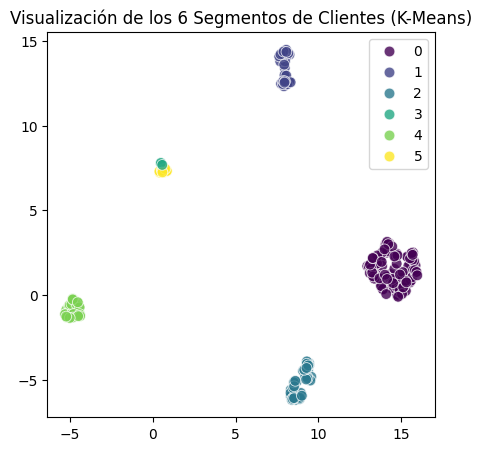

In [92]:
# Reducimos dimensiones
reducer = UMAP(random_state=42)
embedding = reducer.fit_transform(scaled_ds)

# Graficamos
plt.figure(figsize=(5, 5))
sns.scatterplot(
    x=embedding[:, 0], 
    y=embedding[:, 1], 
    hue=clusters, 
    palette='viridis', 
    s=60, 
    alpha=0.8
)
plt.title("Visualización de los 6 Segmentos de Clientes (K-Means)")
plt.show()

Segmentando con KMedoids

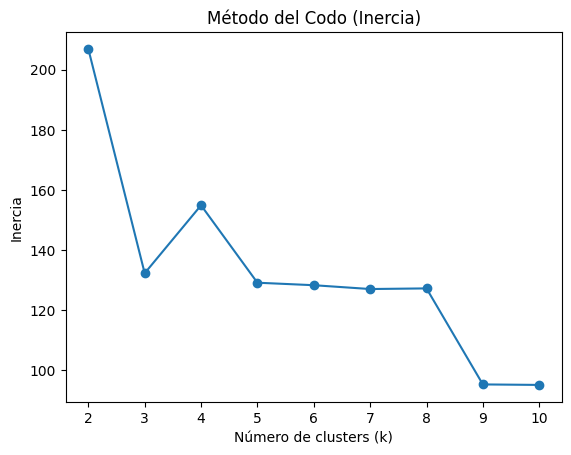

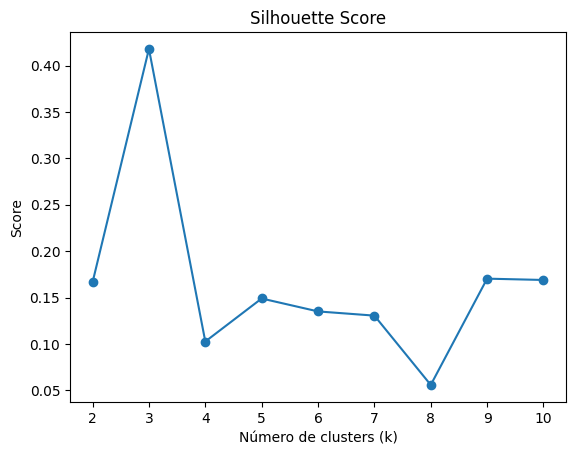

In [93]:
inertia = []
silhouette = []
K_range = range(2, 11)  # desde 2 hasta 10 clusters

for k in K_range:
    kmedoids = KMedoids(n_clusters=k, random_state=42)
    kmedoids.fit(scaled_ds)
    
    inertia.append(kmedoids.inertia_)
    silhouette.append(silhouette_score(scaled_ds, kmedoids.labels_))

# 📊 Gráfico método del codo
plt.figure()
plt.plot(K_range, inertia, marker='o')
plt.title("Método del Codo (Inercia)")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.show()

# 📊 Gráfico silhouette
plt.figure()
plt.plot(K_range, silhouette, marker='o')
plt.title("Silhouette Score")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Score")
plt.show()

k=3 es el número óptimo de clusters, ya que representa el punto de equilibrio donde la inercia del Método del Codo comienza a estabilizarse y, simultáneamente, se alcanza el valor máximo en el Silhouette Score (superior a 0.40). 

In [94]:
k_optimo = 3
kmedoids = KMedoids(n_clusters=k_optimo, random_state=42)
clusters = kmedoids.fit_predict(scaled_ds)
df_final["Clusters_KMedoids"] = clusters

## Guardamos los resultados en el dataset original para poder interpretarlos
df_final.groupby("Clusters_KMedoids").mean()

,hls,venta_id,is_COSTA,LATA,NR,RB,CORE,PREMIUM & SP,VALUE,1,2,4,6,10,12,24,grande,mediano,otros,pequeño,total_marcas,marcas_mias,ratio_marcas_mias,Clusters_KMeans
Clusters_KMedoids,,,,,,,,,,,,,,,,,,,,,,,,
0,2012.914936,581315.921538,0.892308,0.561538,0.438462,0.00000,0.297941,0.687315,0.014744,0.284967,0.001828,0.001051,0.577970,0.025406,0.101656,0.007121,0.6,0.338462,0.061538,0.000000,27.261538,9.076923,0.335999,1.815385
1,110.782770,33482.845455,0.000000,0.567701,0.432299,0.00000,0.350289,0.649086,0.000624,0.216452,0.000224,0.000192,0.670923,0.032090,0.067953,0.012165,0.0,0.090909,0.030303,0.878788,16.272727,7.545455,0.468893,3.757576
2,411.079777,116067.186111,1.000000,0.576098,0.421712,0.00219,0.397593,0.602407,0.000000,0.161091,0.000016,0.000024,0.730028,0.035935,0.064338,0.008568,0.0,0.064815,0.083333,0.851852,14.555556,7.259259,0.491923,0.444444


Graficamos los clusters

c:\Users\bryan\AppData\Local\Programs\Python\Python311\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


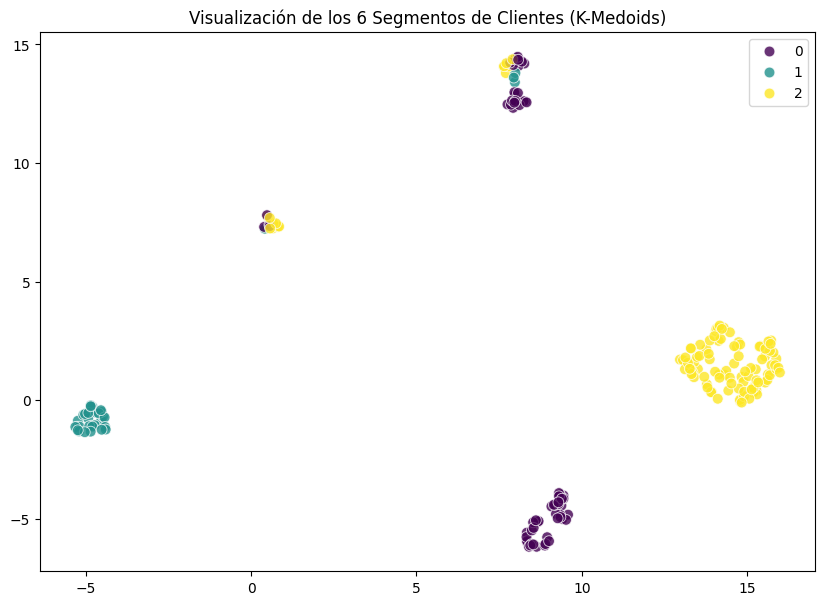

In [95]:
# Reducimos dimensiones
reducer = UMAP(random_state=42)
embedding = reducer.fit_transform(scaled_ds)

# Graficamos
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=embedding[:, 0], 
    y=embedding[:, 1], 
    hue=clusters, 
    palette='viridis', 
    s=60, 
    alpha=0.8
)
plt.title("Visualización de los 6 Segmentos de Clientes (K-Medoids)")
plt.show()

Segmentando con DBSCAN

In [96]:
# Definir rangos de búsqueda
eps_values = np.arange(0.2, 1.5, 0.1) # De 0.2 a 1.5 saltando de 0.1 en 0.1
min_samples_values = np.arange(10,60,10)

resultados = []

for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(scaled_ds)
        
        # Silhouette solo funciona si hay entre 2 y (N-1) clusters
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        
        if n_clusters > 1:
            score = silhouette_score(scaled_ds, labels)
            resultados.append({
                'eps': eps,
                'min_samples': min_samples,
                'n_clusters': n_clusters,
                'silhouette': score
            })

# Convertir a DataFrame para ver el mejor
df_res = pd.DataFrame(resultados)
mejor_combinacion = df_res.sort_values(by='silhouette', ascending=False).head(1)

print("Mejor resultado encontrado:")
print(mejor_combinacion)

Mejor resultado encontrado:
    eps  min_samples  n_clusters  silhouette
16  1.0           10           5    0.584343


In [97]:
#Usamos la ultima comninacion
db = DBSCAN(eps=1.0, min_samples=10)
clusters_umap = db.fit_predict(umap_data)

c:\Users\bryan\AppData\Local\Programs\Python\Python311\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


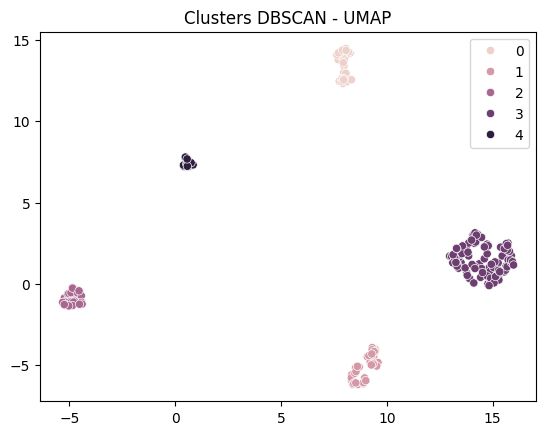

In [98]:
# UMAP
umap = UMAP(random_state=42)
umap_data = umap.fit_transform(scaled_ds)
sns.scatterplot(x=umap_data[:,0], y=umap_data[:,1], hue=clusters_umap)
plt.title("Clusters DBSCAN - UMAP")
plt.show()

In [99]:
df_final["cluster"] = clusters_umap
df_final.groupby("cluster").mean()

,hls,venta_id,is_COSTA,LATA,NR,RB,CORE,PREMIUM & SP,VALUE,1,2,4,6,10,12,24,grande,mediano,otros,pequeño,total_marcas,marcas_mias,ratio_marcas_mias,Clusters_KMeans,Clusters_KMedoids
cluster,,,,,,,,,,,,,,,,,,,,,,,,,
0,1577.025180,452714.240625,0.906250,0.570579,0.429421,0.000000,0.329440,0.662032,0.008528,0.245440,0.000616,0.000307,0.612778,0.024853,0.109077,0.006929,0.0,1.0,0.0,0.0,23.343750,8.656250,0.382445,1.000000,0.531250
1,2259.992636,654206.241026,0.820513,0.557694,0.442306,0.000000,0.291286,0.691416,0.017298,0.298751,0.002512,0.001470,0.567861,0.020971,0.101238,0.007197,1.0,0.0,0.0,0.0,28.897436,9.307692,0.327809,2.000000,0.000000
2,86.387713,25856.910345,0.000000,0.567145,0.432855,0.000000,0.356368,0.643632,0.000000,0.216139,0.000000,0.000000,0.676620,0.032182,0.062289,0.012769,0.0,0.0,0.0,1.0,15.482759,7.517241,0.484483,4.000000,1.000000
3,367.255386,103734.464130,1.000000,0.577693,0.419737,0.002571,0.410626,0.589374,0.000000,0.159797,0.000000,0.000000,0.737857,0.031443,0.062339,0.008564,0.0,0.0,0.0,1.0,14.369565,7.304348,0.507870,0.000000,2.000000
4,285.332882,80814.621429,0.928571,0.560652,0.439348,0.000000,0.275095,0.722660,0.002245,0.184918,0.000732,0.000717,0.663655,0.082301,0.058456,0.009220,0.0,0.0,1.0,0.0,16.857143,6.642857,0.331731,4.571429,1.357143
